# Task 2.2: Predicting Rainfall Data

## 2.3.1 Spark Session

In [ ]:
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark import StorageLevel
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from datetime import datetime, timedelta

import matplotlib.pyplot as plt

import time

In [2]:
# Use the existing Dataproc cluster.
spark = (
    SparkSession.builder
    .appName("Rainfall_GBT_Experiments")
    .getOrCreate()
)
 
spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")
spark.conf.set("spark.sql.shuffle.partitions", "128")
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.adaptive.coalescePartitions.enabled", "true")

ML_PARTITIONS = 32
 
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))
print("Training partitions:", ML_PARTITIONS)
 

Spark version: 3.5.3
Spark master: yarn
Shuffle partitions: 128
Training partitions: 32


26/10/16 14:38:17 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


## 2.3.2 Reading Station Mapping and Test Dataset

In [ ]:
# Mapping Table from station_id to latitude and longitude
# Not required as the test dataframe contains the coordinates and timestamp
## station_locations = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/station_mapping/")

train_final = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/train_parquet/")
val_final = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/val_parquet/")
test_final = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/test_parquet/")
test = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/full_test_parquet/")

# Combine Train and Val as a full training set
full_train = train_final.union(val_final)

## 2.3.3 Training the Final Model

In [6]:
feature_cols = [
    "location_latitude",
    "location_longitude",
    "hour",
    "month",
    "reading_value",
    "lag_5m",
    "lag_30m",
    "lag_1h",
    "rain_cumsum_30m",
    "rain_cumsum_1h",
    "wet_count_30m",
    "thr"
]

In [ ]:
# Function to train the GBT model based on the best set 
# of Hyper-parameters during Grid Search
def train_gbt(depth, learning_rate, iterations):
 
    # STEP 1: Combine the input columns into a feature vector.
    assembler = VectorAssembler(
        inputCols=feature_cols,
        outputCol="features"
    )
 
    # STEP 2: Configure this grid combination.
    gbt = GBTClassifier(
        maxDepth=depth,
        stepSize=learning_rate,
        maxIter=iterations,
        seed=42
    )
 
    pipeline = Pipeline(stages=[assembler, gbt])
 
    # STEP 3: Train using the prepared training sample.
    # This timer measures fitting only, excluding evaluation and saving.
    start = time.perf_counter()
    model = pipeline.fit(full_train)
    training_seconds = time.perf_counter() - start

    # STEP 4: Generate validation predictions.
    # Cache them because the metric calculations reuse them.
    predictions = (
        model.transform(test_final)
        .select("thr", "label", "rawPrediction")
        .persist(StorageLevel.MEMORY_AND_DISK)
    )

    # STEP 5: Evaluate the Model
    pr_evaluator = BinaryClassificationEvaluator(
        metricName="areaUnderPR"
    )
 
    roc_evaluator = BinaryClassificationEvaluator(
        metricName="areaUnderROC"
    )

    auc_pr = pr_evaluator.evaluate(predictions)
    auc_roc = roc_evaluator.evaluate(predictions)

    print(
        f"Depth={depth}, "
        f"Learning rate={learning_rate}, "
        f"Iterations={iterations} | "
        f"Average PR-AUC={auc_pr:.4f} | "
        f"Average ROC-AUC={auc_roc:.4f} | "
        f"Training time={training_seconds:.1f}s"
    )

    # STEP 6: Save the Final Model Trained on Train and Val set.

    OUTPUT = (
        "gs://dsa5208-rainfall-sixing-data/task2"
    )
    
    MODEL_PATH = OUTPUT + "/final_model"
    print("Saving to:", MODEL_PATH)

    model.write().overwrite().save(MODEL_PATH)
 
 

In [ ]:
# Best combination.
#train_gbt(depth=3, learning_rate=0.01, iterations=150)

26/10/16 13:53:09 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Depth=3, Learning rate=0.01, Iterations=150 | Average PR-AUC=0.5706 | Average ROC-AUC=0.9070 | Training time=228.3s
Saving to: gs://dsa5208-rainfall-sixing-data/task2


## 2.3.4 Loading the Final Model for Rainfall Prediction

In [ ]:
OUTPUT = ("gs://dsa5208-rainfall-sixing-data/task2")

MODEL_PATH = OUTPUT + "/final_model"
model = PipelineModel.load(MODEL_PATH)

## 2.3.5 Feature Importance of the Final Model Trained

+------------------+--------------------+
|feature           |importance          |
+------------------+--------------------+
|reading_value     |0.4024099966390228  |
|thr               |0.3730995798065325  |
|rain_cumsum_30m   |0.1309168835751719  |
|rain_cumsum_1h    |0.03942772211916704 |
|lag_5m            |0.02625042273537816 |
|lag_1h            |0.01941459117374884 |
|wet_count_30m     |0.008480803950978664|
|lag_30m           |0.0                 |
|location_latitude |0.0                 |
|month             |0.0                 |
|location_longitude|0.0                 |
|hour              |0.0                 |
+------------------+--------------------+



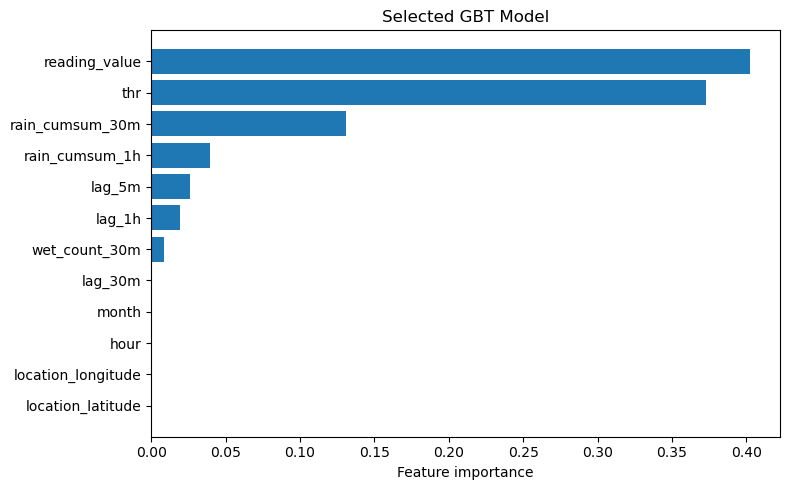

In [ ]:

names = model.stages[0].getInputCols()
values = model.stages[-1].featureImportances.toArray()
 
importance = spark.createDataFrame(
    [(name, float(value)) for name, value in zip(names, values)],
    ["feature", "importance"]
)
 
importance.orderBy(F.desc("importance")).show(truncate=False)
 
importance.coalesce(1).write.mode("overwrite").parquet(
    OUTPUT + "/feature_importance"
)
 
# Collect only the small feature-importance table for plotting.
plot_data = importance.toPandas().sort_values("importance")
 
plt.figure(figsize=(8, 5))
plt.barh(plot_data["feature"], plot_data["importance"])
plt.xlabel("Feature importance")
plt.title("Final GBT Model")
plt.tight_layout()
plt.show()

## 2.3.6 Predicting Probability of Rainfall Higher than Threshold in Next 30 Mins

In [54]:
def predict_rainfall(station_id, pred_time, threshold):

    row = (test
        .filter(F.col("station_id") == station_id)
        .filter(F.col("timestamp") <= F.lit(pred_time).cast("timestamp"))
        .orderBy(F.desc("timestamp"))
        .limit(1)
        .withColumn("thr", F.lit(float(threshold))))

    print(row.show())

    scored = model.transform(row).select("probability").first()

    if scored is None:
        raise ValueError(f"No readings for {station_id} before {pred_time}")

    return float(scored["probability"][1])

In [55]:
predicted_prob = predict_rainfall("S06", "2024-11-07 16:52:00", 0.5)
print(f"Predicted Probability : {predicted_prob}")

+----------+-------------------+----+-----------------+------------------+----+-----+-------------+------+-------+------+---------------+--------------+-------------+----------+---+
|station_id|          timestamp|year|location_latitude|location_longitude|hour|month|reading_value|lag_5m|lag_30m|lag_1h|rain_cumsum_30m|rain_cumsum_1h|wet_count_30m|future_30m|thr|
+----------+-------------------+----+-----------------+------------------+----+-----+-------------+------+-------+------+---------------+--------------+-------------+----------+---+
|       S06|2024-11-07 16:50:00|2024|           1.3524|          103.9007|  16|   11|          0.2|   0.2|    0.2|   0.0|            5.0|           5.2|            6|       0.4|0.5|
+----------+-------------------+----+-----------------+------------------+----+-----+-------------+------+-------+------+---------------+--------------+-------------+----------+---+

None


Predicted Probability : 0.7168039898470735


In [56]:
predicted_prob = predict_rainfall("S116", "2024-01-07 16:57:00", 0.5)
print(f"Predicted Probability : {predicted_prob}")

+----------+-------------------+----+-----------------+------------------+----+-----+-------------+------+-------+------+---------------+--------------+-------------+----------+---+
|station_id|          timestamp|year|location_latitude|location_longitude|hour|month|reading_value|lag_5m|lag_30m|lag_1h|rain_cumsum_30m|rain_cumsum_1h|wet_count_30m|future_30m|thr|
+----------+-------------------+----+-----------------+------------------+----+-----+-------------+------+-------+------+---------------+--------------+-------------+----------+---+
|      S116|2024-01-07 16:55:00|2024|            1.281|           103.754|  16|    1|          0.0|   0.0|    0.0|   0.0|            0.4|           0.8|            2|       0.4|0.5|
+----------+-------------------+----+-----------------+------------------+----+-----+-------------+------+-------+------+---------------+--------------+-------------+----------+---+

None


Predicted Probability : 0.458798785712795


In [57]:
predicted_prob = predict_rainfall("S221", "2024-11-07 16:30:00", 1)
print(f"Predicted Probability : {predicted_prob}")

+----------+-------------------+----+-----------------+------------------+----+-----+-------------+------+-------+------+------------------+------------------+-------------+----------+---+
|station_id|          timestamp|year|location_latitude|location_longitude|hour|month|reading_value|lag_5m|lag_30m|lag_1h|   rain_cumsum_30m|    rain_cumsum_1h|wet_count_30m|future_30m|thr|
+----------+-------------------+----+-----------------+------------------+----+-----+-------------+------+-------+------+------------------+------------------+-------------+----------+---+
|      S221|2024-11-07 16:30:00|2024|          1.35691|         103.89088|  16|   11|        1.584|  4.95|    0.0|   0.0|10.097999999999999|10.097999999999999|            4|     1.188|1.0|
+----------+-------------------+----+-----------------+------------------+----+-----+-------------+------+-------+------+------------------+------------------+-------------+----------+---+

None


Predicted Probability : 0.8395361602119706
